In [2]:
%% In class activity for 22 October 2026
% Ely Dawson
% fft and complex analysis 

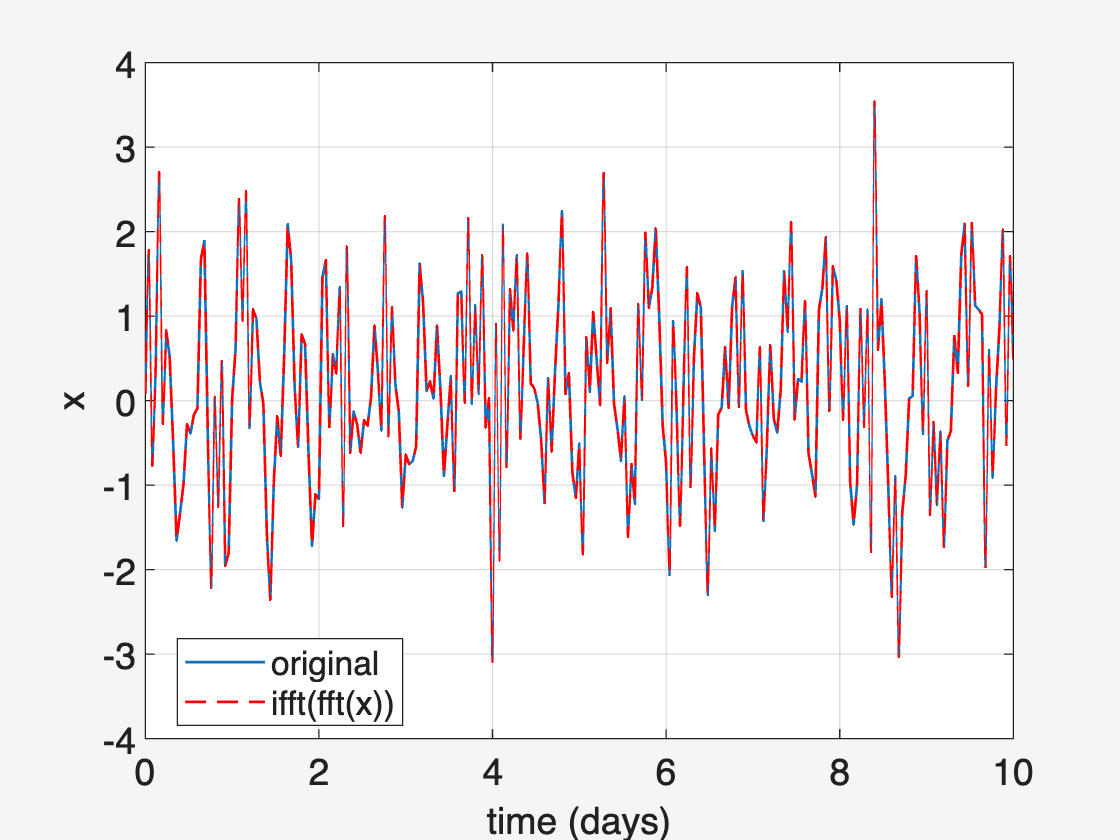

round trip through fft/ifft: max error = 1.887e-15


In [4]:
rng(221)
dt = 0.04;
time = 0:dt:10; 
N = length(time);
P = 12.42/24; %semidiurnal period, in days
x = randn(size(time)) + sin(2*pi*time/P);
X = fft(x);
x_new = ifft(X);

figure(1); clf
plot(time, x, 'LineWidth', 1)
hold on
plot(time, real(x_new), 'r--', 'LineWidth', 1)
hold off
xlabel('time (days)','FontSize',14); ylabel('x','FontSize',14)
legend('original','ifft(fft(x))','Location','best')
grid on
fprintf('round trip through fft/ifft: max error = %.3e\n', max(abs(x - x_new)));

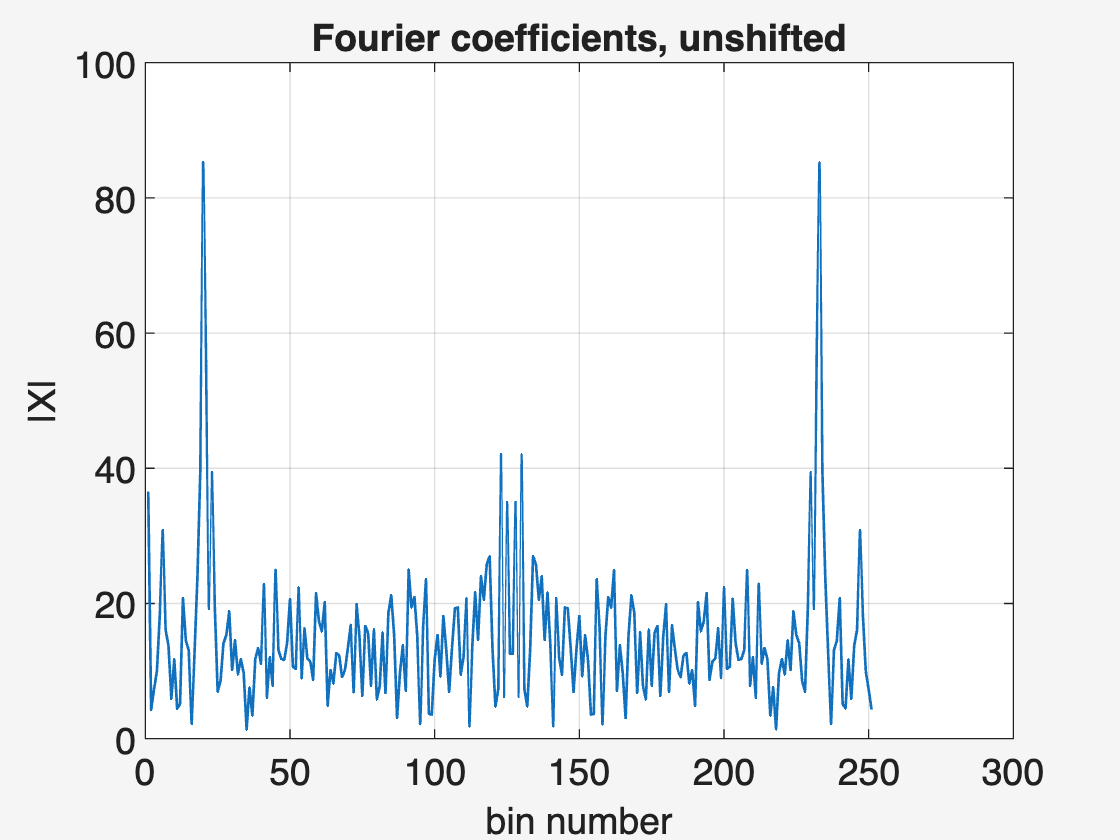

In [5]:
%The Fourier coefficients, against bin number.
figure(2); clf
plot(abs(X), 'LineWidth', 1)
xlabel('bin number','FontSize',14)
ylabel('|X|','FontSize',14)
title('Fourier coefficients, unshifted','FontSize',14)
grid on;

N = 251, df = 0.0996 cpd, Nyquist = 12.50 cpd
smallest |f| on the grid = 0.000e+00 (should be exactly 0)


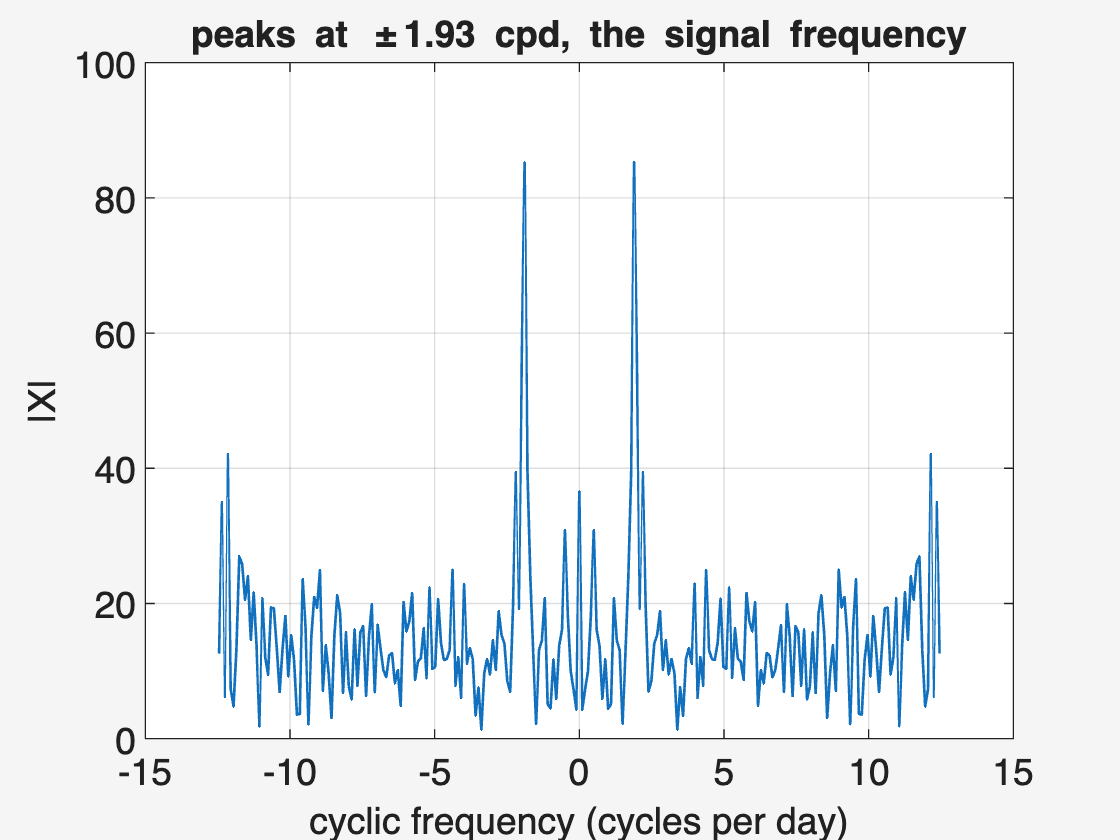

In [8]:
T = dt*N;
df = 1/T;
fn = 1/2/dt; %the Nyquist frequency
%Build the (shifted) frequency axis from the sample indices. This is correct
%for both even and odd N; zero frequency lands exactly on the grid.
k = -floor(N/2):floor((N-1)/2);
f = k*df;
fprintf('N = %d, df = %.4f cpd, Nyquist = %.2f cpd\n', N, df, fn);
fprintf('smallest |f| on the grid = %.3e (should be exactly 0)\n',min(abs(f)));
%MATLAB puts zero frequency first, so shift to put it in the middle.
Xs = fftshift(X);
figure(3); clf
plot(f, abs(Xs), 'LineWidth', 1)
xlabel('cyclic frequency (cycles per day)','FontSize',14)
ylabel('|X|','FontSize',14)
grid on
title(sprintf('peaks at \\pm%.2f cpd, the signal frequency', 1/P),'FontSize',14)

In [9]:
lhs = sum(x.^2);
rhs = sum(abs(X).^2);
fprintf('sum |x|^2 = %12.4f\n', lhs);
fprintf('sum |X|^2 = %12.4f\n', rhs);
fprintf('ratio = %12.4f (N = %d)\n', rhs/lhs, N);
fprintf('sum |X|^2 / N = %12.4f\n', rhs/N);

sum |x|^2 =     336.4584
sum |X|^2 =   84451.0471
ratio =     251.0000 (N = 251)
sum |X|^2 / N =     336.4584


In [ ]:
%% never FFT anything that you have not looked at in the time domain first!! 